# Iris Flower Classification (CodeAlpha Data Science Internship, Task 1)

**Goal:** train a machine learning model that classifies an Iris flower as *setosa*, *versicolor* or *virginica* from four measurements, then evaluate how well it works on data it has not seen.

**Data:** 150 flowers, 50 per species, with sepal length/width and petal length/width in cm.

**Contents**
1. Load and inspect
2. Explore the data
3. Train / test split
4. Train three models
5. Evaluate on the test set
6. Which measurements matter
7. Predict a new flower
8. Conclusions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'font.size': 10,
})
pd.set_option('display.width', 120)

## 1. Load and inspect

In [2]:
raw = pd.read_csv('Iris.csv')
print('Shape:', raw.shape)
raw.head()

Shape: (150, 6)


   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

In [3]:
df = raw.drop(columns='Id').copy()                       # Id is just a row number
df['Species'] = df['Species'].str.replace('Iris-', '', regex=False)
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows (ignoring Id):', int(df.duplicated().sum()))
print()
print(df['Species'].value_counts().to_string())

Missing values: 0
Duplicate rows (ignoring Id): 3

Species
setosa        50
versicolor    50
virginica     50


No missing values, and the three species are perfectly balanced (50 each), so plain accuracy is a fair metric. A few measurement rows repeat exactly; they are separate flowers with identical readings, so they are kept.

In [4]:
df.groupby('Species')[features].agg(['mean', 'std']).round(2).T

Species             setosa  versicolor  virginica
SepalLengthCm mean    5.01        5.94       6.59
              std     0.35        0.52       0.64
SepalWidthCm  mean    3.42        2.77       2.97
              std     0.38        0.31       0.32
PetalLengthCm mean    1.46        4.26       5.55
              std     0.17        0.47       0.55
PetalWidthCm  mean    0.24        1.33       2.03
              std     0.11        0.20       0.27

## 2. Explore the data

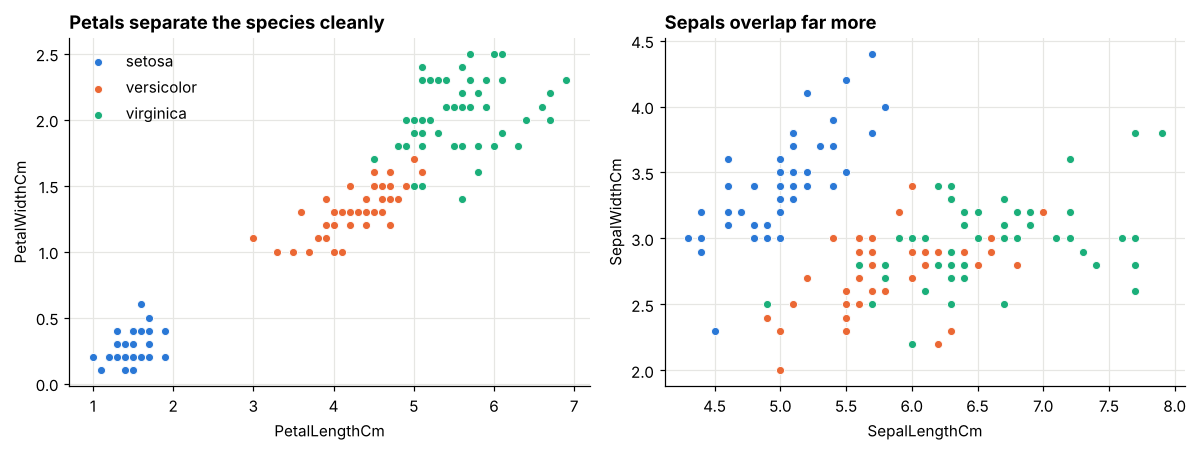

In [5]:
colors = {'setosa': BLUE, 'versicolor': ORANGE, 'virginica': AQUA}
pairs = [('PetalLengthCm', 'PetalWidthCm'), ('SepalLengthCm', 'SepalWidthCm')]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (xcol, ycol) in zip(axes, pairs):
    for sp, g in df.groupby('Species'):
        ax.scatter(g[xcol], g[ycol], s=28, color=colors[sp], edgecolor='white', linewidth=0.6, label=sp)
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
axes[0].set_title('Petals separate the species cleanly')
axes[1].set_title('Sepals overlap far more')
axes[0].legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

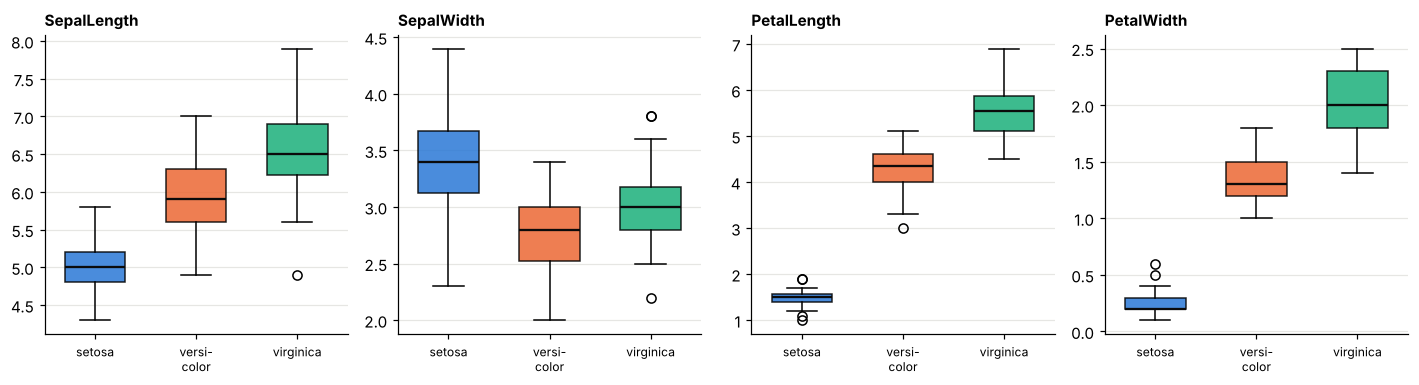

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
order = ['setosa', 'versicolor', 'virginica']
for ax, col in zip(axes, features):
    data = [df.loc[df['Species'] == s, col] for s in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={'color': '#0b0b0b', 'lw': 1.5})
    for patch, s in zip(bp['boxes'], order):
        patch.set_facecolor(colors[s])
        patch.set_alpha(0.85)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['setosa', 'versi-\ncolor', 'virginica'], fontsize=8)
    ax.set_title(col.replace('Cm', ''), fontsize=10)
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

In [7]:
df[features].corr().round(2)

               SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm           1.00         -0.11           0.87          0.82
SepalWidthCm           -0.11          1.00          -0.42         -0.36
PetalLengthCm           0.87         -0.42           1.00          0.96
PetalWidthCm            0.82         -0.36           0.96          1.00

Setosa is clearly separate on the petal measurements. Versicolor and virginica sit next to each other with a small overlap, which is where any mistakes will come from. Petal length and petal width are very strongly correlated.

## 3. Train / test split

In [8]:
X = df[features]
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape[0], 'flowers   Test:', X_test.shape[0], 'flowers')
print('Test set per species:', y_test.value_counts().to_dict())

Train: 120 flowers   Test: 30 flowers
Test set per species: {'setosa': 10, 'virginica': 10, 'versicolor': 10}


80% of the flowers are used for training and 20% are held back for testing. `stratify=y` keeps the species balanced in both parts.

## 4. Train three models

- **Logistic regression** is a simple linear baseline.
- **K-nearest neighbours** classifies a flower by the species of its 5 closest neighbours.
- **Random forest** combines many decision trees.

Logistic regression and KNN depend on feature scale, so they are wrapped in a pipeline with `StandardScaler`.

In [9]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'K-Nearest Neighbours': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
preds, rows = {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    cv = cross_val_score(model, X, y, cv=skf)
    rows.append({'Model': name,
                 'Test accuracy': accuracy_score(y_test, preds[name]),
                 '5-fold CV mean': cv.mean(),
                 '5-fold CV std': cv.std()})

results = pd.DataFrame(rows).set_index('Model').round(3)
results

                      Test accuracy  5-fold CV mean  5-fold CV std
Model                                                             
Logistic Regression           0.933           0.953          0.045
K-Nearest Neighbours          0.933           0.973          0.025
Random Forest                 0.900           0.960          0.039

The test set has only 30 flowers, so one mistake moves its accuracy by about 3 points. The 5-fold cross-validation score (every flower is tested once, across five different splits) is a steadier estimate, so both are shown.

## 5. Evaluate on the test set

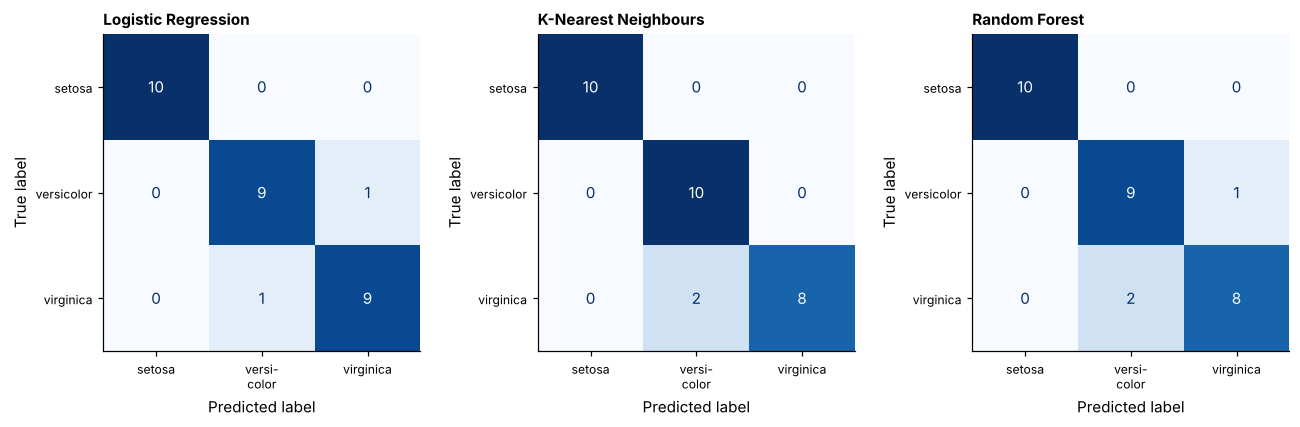

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=order, ax=ax,
                                            cmap='Blues', colorbar=False)
    ax.set_title(name, fontsize=10)
    ax.grid(False)
    ax.set_xticklabels(['setosa', 'versi-\ncolor', 'virginica'], fontsize=8)
    ax.set_yticklabels(['setosa', 'versicolor', 'virginica'], fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
best_name = results['5-fold CV mean'].idxmax()
print('Best model by cross-validation:', best_name)
print()
print(classification_report(y_test, preds[best_name], digits=3))

Best model by cross-validation: K-Nearest Neighbours

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30


In [12]:
for name, pred in preds.items():
    wrong = X_test[pred != y_test].copy()
    wrong['Actual'] = y_test[pred != y_test]
    wrong['Predicted'] = pred[pred != y_test]
    print(f'{name}: {len(wrong)} misclassified')
    if len(wrong):
        print(wrong.to_string())
    print()

Logistic Regression: 2 misclassified
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Actual   Predicted
134            6.1           2.6            5.6           1.4   virginica  versicolor
77             6.7           3.0            5.0           1.7  versicolor   virginica

K-Nearest Neighbours: 2 misclassified
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm     Actual   Predicted
138            6.0           3.0            4.8           1.8  virginica  versicolor
134            6.1           2.6            5.6           1.4  virginica  versicolor

Random Forest: 3 misclassified
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Actual   Predicted
138            6.0           3.0            4.8           1.8   virginica  versicolor
134            6.1           2.6            5.6           1.4   virginica  versicolor
77             6.7           3.0            5.0           1.7  versicolor   virginica


## 6. Which measurements matter

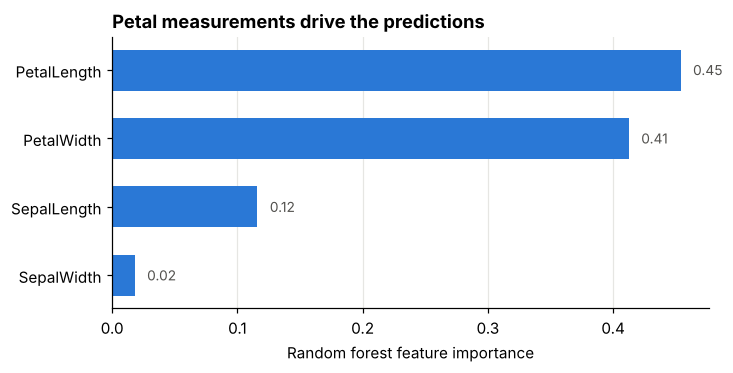

In [13]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=features).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(imp.index.str.replace('Cm', ''), imp.values, color=BLUE, height=0.6)
for y_, v in enumerate(imp.values):
    ax.text(v + 0.01, y_, f'{v:.2f}', va='center', fontsize=9, color='#52514e')
ax.set_xlabel('Random forest feature importance')
ax.set_title('Petal measurements drive the predictions')
ax.grid(axis='y', visible=False)
plt.show()

## 7. Predict a new flower

In [14]:
final_model = models[best_name]
new_flowers = pd.DataFrame([[5.0, 3.4, 1.5, 0.2],
                            [6.0, 2.9, 4.5, 1.5],
                            [6.9, 3.1, 5.8, 2.2]], columns=features)
new_flowers['Predicted species'] = final_model.predict(new_flowers[features])
new_flowers

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Predicted species
0            5.0           3.4            1.5           0.2            setosa
1            6.0           2.9            4.5           1.5        versicolor
2            6.9           3.1            5.8           2.2         virginica

## 8. Conclusions

### Results

| Model | Test accuracy (30 flowers) | 5-fold CV accuracy |
|---|---|---|
| K-Nearest Neighbours | 93.3% | 97.3% (± 2.5) |
| Random Forest | 90.0% | 96.0% (± 3.9) |
| Logistic Regression | 93.3% | 95.3% (± 4.5) |

### What we learned

- **All three models classify Iris flowers well**, scoring 90% to 93% on the held-out test set and 95% to 97% under cross-validation. K-Nearest Neighbours has the best cross-validated score, but the gaps between models are small (one flower on the test set, and within the fold-to-fold spread), so none is clearly better than the others.
- **Setosa is never confused with the other species.** Every error is between versicolor and virginica, whose measurements overlap slightly.
- **The hardest flowers are borderline cases.** KNN and the random forest both misclassify the same two virginica flowers (6.1, 2.6, 5.6, 1.4 and 6.0, 3.0, 4.8, 1.8), which have measurements typical of versicolor.
- **Petal measurements do most of the work.** Petal length and width account for about 86% of the random forest's feature importance; sepal width adds almost nothing.

### Caveats and next steps

- Iris is a small, easy benchmark (150 flowers, well-separated classes), so these scores will not carry over to harder problems.
- Results come from one random split plus cross-validation. Tuning `k` for KNN and the forest's settings with a grid search, and repeating the split with several seeds, would show how stable the ranking is.